In [81]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
from langgraph.prebuilt import ToolNode, tools_condition
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.tools import tool
import requests
import random

In [82]:
load_dotenv()

True

In [83]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [84]:
# Tools
search_tool = DuckDuckGoSearchRun(region="us-en")


@tool
def calculator(
    first_num: float,
    second_num: float,
    operation: str
) -> dict:
    """
    Perform a basic arithmetic operation on two numbers.
    Supported operations: add, sub, mul, div.
    """
    try:
        if operation == "add":
            result = first_num + second_num
        elif operation == "sub":
            result = first_num - second_num
        elif operation == "mul":
            result = first_num * second_num
        elif operation == "div":
            if second_num == 0:
                return {"error": "Division by zero is not allowed"}
            result = first_num / second_num
        else:
            return {"error": f"Unsupported operation '{operation}'"}

        return {
            "first_num": first_num,
            "second_num": second_num,
            "operation": operation,
            "result": result
        }

    except Exception as e:
        return {"error": str(e)}


@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL', 'TSLA') 
    using Alpha Vantage with API key in the URL.
    """
    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=YFHKA515NYH1AZ1X"
    r = requests.get(url)
    return r.json()


 

In [85]:
# Make tool list
tools = [get_stock_price, search_tool, calculator]

# Make the LLM tool-aware
llm_with_tools = llm.bind_tools(tools)

In [86]:
# State
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [87]:
# Graph nodes
def chat_node(state: ChatState):
    """LLM node that may perform a tool call."""
    messages = state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


tool_node = ToolNode(tools)  # Executes tool calls

In [88]:
#graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tool_node", tool_node)


In [89]:
graph.add_edge(START, "chat_node")

#If the LLM asked for a tool call, go to the tool node. Otherwise, end the graph.
graph.add_conditional_edges("chat_node", tools_condition, {"tools": "tool_node", END: END})

graph.add_edge("tool_node", "chat_node")

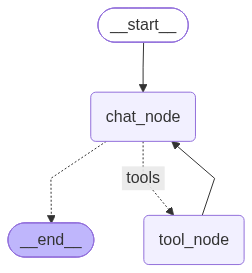

In [90]:
chatbot = graph.compile()

chatbot 

In [91]:
#Regular chat

out = chatbot.invoke({"messages": [HumanMessage(content="Hello!")]})

print(out["messages"][-1].content)

Hello! How can I assist you today?


In [92]:
# Chat requiring tool

out = chatbot.invoke({
    "messages": [
        HumanMessage(content="What is 2*3?")
    ]
})
print(out["messages"][-1].content)

2 × 3 = 6.


In [93]:
# Chat requiring tool

out = chatbot.invoke({
    "messages": [
        HumanMessage(content="What is the stock price of apple")
    ]
})
print(out["messages"][-1].content)

Apple (AAPL) is currently trading at **$347.73 per share** (price reported for the latest trading day, 2026‑10‑23).
